# Linear Regression — Production Pipeline
## 1. Overview
In this notebook, we build a complete **Linear Regression** pipeline to predict continuous values:
- **Step 1:** Load and clean a real-world continuous dataset using `pandas`.
- **Step 2:** Exploratory Data Analysis (EDA) using scatter plots to inspect relationships between features and the target.
- **Step 3:** Split the data into **Train / Test** sets, train `LinearRegression`, and compute predictions ($y = mx + b$).
- **Step 4:** Evaluate the model using **MSE, RMSE, and MAE**.
- **Step 5:** Plot the **Regression Line** against actual data points and interpret the results.

In [1]:
# Part 1: Load and Clean the Dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Step 1: Load real-world continuous dataset into pandas
raw_data = load_diabetes(as_frame=True)
df = raw_data.frame

print("Shape before cleaning:", df.shape)
print("Total missing values:", df.isnull().sum().sum())

# Step 2: Clean missing values and duplicates
df = df.dropna().drop_duplicates()

# Step 3: Encode categorical variables if any exist
df = pd.get_dummies(df, drop_first=True)

print("Shape after cleaning:", df.shape)
df.head()

Shape before cleaning: (442, 11)
Total missing values: 0
Shape after cleaning: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


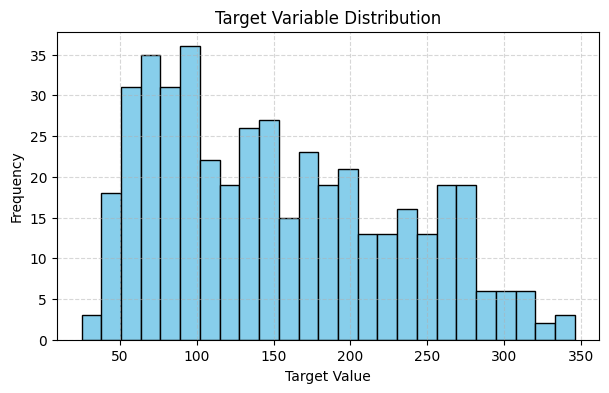

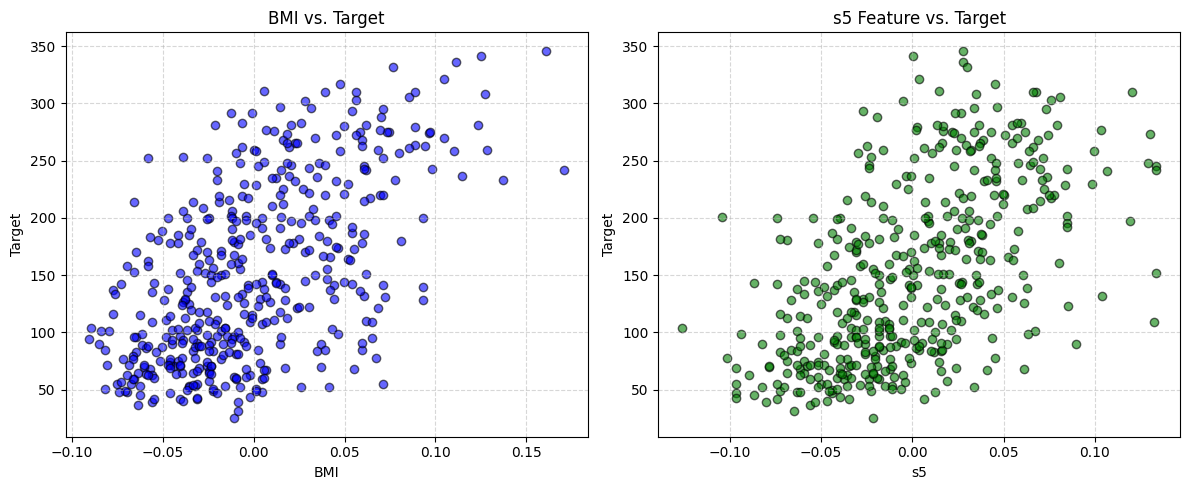

In [2]:
# Part 2: Exploratory Data Analysis (EDA) & Data Distribution

# Step 1: Check target distribution
plt.figure(figsize=(7, 4))
plt.hist(df['target'], bins=25, color='skyblue', edgecolor='black')
plt.title("Target Variable Distribution")
plt.xlabel("Target Value")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Step 2: Scatter plots to visualize relationships between features and target
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(df['bmi'], df['target'], color='blue', alpha=0.6, edgecolor='k')
axes[0].set_title("BMI vs. Target")
axes[0].set_xlabel("BMI")
axes[0].set_ylabel("Target")
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].scatter(df['s5'], df['target'], color='green', alpha=0.6, edgecolor='k')
axes[1].set_title("s5 Feature vs. Target")
axes[1].set_xlabel("s5")
axes[1].set_ylabel("Target")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [3]:
# Part 3: Split into Train / Test & Model Training

X = df.drop('target', axis=1)
y = df['target'].values

# Step 1: Split data into 80% Train and 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

# Step 2: Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept (b):", round(model.intercept_, 4))
print("First 5 Weights (m):", np.round(model.coef_[:5], 4))

# Step 3: Calculate Predictions (Rule: y = b + sum(m * feature))
y_test_manual = model.intercept_ + np.dot(X_test, model.coef_)
y_test_pred   = model.predict(X_test)
y_train_pred  = model.predict(X_train)

print("\nFirst 5 Predictions (Manual y = mx + b):", np.round(y_test_manual[:5], 2))
print("First 5 Predictions (model.predict):    ", np.round(y_test_pred[:5], 2))
print("First 5 Actual Values (y_test):         ", np.round(y_test[:5], 2))

Train samples: 353 | Test samples: 89
Intercept (b): 151.3456
First 5 Weights (m): [  37.904  -241.9644  542.4288  347.7038 -931.4888]

First 5 Predictions (Manual y = mx + b): [139.55 179.52 134.04 291.42 123.79]
First 5 Predictions (model.predict):     [139.55 179.52 134.04 291.42 123.79]
First 5 Actual Values (y_test):          [219.  70. 202. 230. 111.]


In [4]:
# Part 4: Model Evaluation (MSE, RMSE, MAE)

# Step 1: Manual calculation on Test set to show formulas
# MAE  = mean(|y - y_hat|)
# MSE  = mean((y - y_hat)^2)
# RMSE = sqrt(MSE)
manual_mae  = np.mean(np.abs(y_test - y_test_pred))
manual_mse  = np.mean((y_test - y_test_pred) ** 2)
manual_rmse = np.sqrt(manual_mse)

print(f"Test MAE  (Manual): {manual_mae:.4f}")
print(f"Test MSE  (Manual): {manual_mse:.4f}")
print(f"Test RMSE (Manual): {manual_rmse:.4f}\n")

# Step 2: Evaluation table for Train and Test splits
def evaluate_split(y_true, y_pred, split_name):
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    return {
        "Split": split_name,
        "MAE": round(mae, 4),
        "MSE": round(mse, 4),
        "RMSE": round(rmse, 4)
    }

results_df = pd.DataFrame([
    evaluate_split(y_train, y_train_pred, "Train"),
    evaluate_split(y_test, y_test_pred, "Test")
])

print("=== Evaluation Metrics Table ===")
display(results_df)

Test MAE  (Manual): 42.7941
Test MSE  (Manual): 2900.1936
Test RMSE (Manual): 53.8534

=== Evaluation Metrics Table ===


,Split,MAE,MSE,RMSE
0,Train,43.4835,2868.5497,53.5588
1,Test,42.7941,2900.1936,53.8534


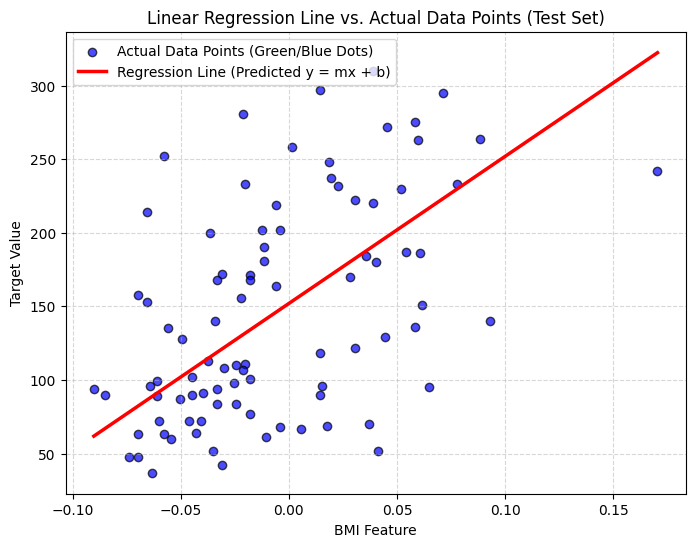

In [5]:
# Part 5: Regression Line Visualization (y = mx + b)

# Train a 1D Linear Regression on 'bmi' to plot the straight fitted line
X_train_1d = X_train[['bmi']].values
X_test_1d  = X_test[['bmi']].values

model_1d = LinearRegression()
model_1d.fit(X_train_1d, y_train)

x_line = np.linspace(X_test_1d.min(), X_test_1d.max(), 100).reshape(-1, 1)
y_line = model_1d.predict(x_line)

plt.figure(figsize=(8, 6))
plt.scatter(X_test_1d, y_test, color='blue', edgecolor='k', alpha=0.7, label='Actual Data Points (Green/Blue Dots)')
plt.plot(x_line, y_line, color='red', linewidth=2.5, label='Regression Line (Predicted y = mx + b)')
plt.title("Linear Regression Line vs. Actual Data Points (Test Set)")
plt.xlabel("BMI Feature")
plt.ylabel("Target Value")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 3. Results & Interpretation
- **Linear Equation ($y = mx + b$):** Using Least Squares optimization, the model learns the best-fitting line (or plane in multiple dimensions) that minimizes the distance between the actual data points and the predicted values on the line.
- **Mean Absolute Error (MAE):** Calculates the average absolute difference $\frac{1}{n}\sum |y_i - \hat{y}_i|$ so positive and negative errors do not cancel out, making it robust to outliers.
- **MSE & RMSE:** **MSE** squares the errors $\frac{1}{n}\sum (y_i - \hat{y}_i)^2$ to heavily penalize large deviations and remain differentiable for optimization, while **RMSE** takes the square root ($\sqrt{\text{MSE}}$) to return the error to the original target units.